# 06 - Tree models: Random Forest and XGBoost

**Day 5 (Ali):** can a more flexible model beat the logistic regression from Day 4?

| Model | What it is |
|---|---|
| `logit_A` | Day 4 baseline: logistic regression on `distance`, `angle`, `header`, `counter_attack` |
| `rf` | Random Forest on the same features |
| `xgb` | XGBoost on the same features |
| `xgb_mono` | XGBoost with **monotone constraints** (xG never rises with distance, never falls with angle) |

Code: `src/tree_models.py`. Same rules as Day 4:
- **same features** (model A), so the only difference is the type of model
- hyperparameters chosen with **5-fold GroupKFold by match** on train, scored with **log loss**
- the **test set is used once**, at the end (section 8)

Running this notebook takes a few minutes (section 5 and 6 run the grid searches).
Use the **`.venv`** kernel. On macOS, XGBoost needs `brew install libomp`.

## 1. Setup

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path("..").resolve() / "src"))
from model import FEATURES_A, FEATURES_B, cross_validate, fit_logit, load_train_test, predict_xg
from tree_models import (RF_BEST, RF_GRID, XGB_BEST, XGB_GRID, XGB_MONO_BEST, all_test_predictions,
                         bootstrap_difference, cross_validate_estimator, feature_matrix, make_random_forest,
                         make_xgboost, monotone_constraints, tune)
from evaluate import calibration_table, compare_models, evaluate, plot_calibration
from features import distance_to_goal, shot_angle, to_meters
from eda_utils import draw_half_pitch

FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

COLORS = {"logit_A": "#2a6f97", "rf": "#e9c46a", "xgb": "#e76f51", "xgb_mono": "#2a9d8f"}


def save(fig, name):
    """Save a figure into reports/figures."""
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


train, test = load_train_test()
print("train:", train.shape, "| test:", test.shape)

train: (6755, 23) | test: (1696, 23)


## 2. Why log loss and not accuracy?
xG is a **probability**, so we must judge the probabilities, not yes/no answers.
A "model" that says *no goal* for every shot is right 89% of the time and is useless:

In [2]:
always_no = (train["is_goal"] == False).mean()
print(f"Accuracy of 'never a goal': {always_no:.1%}")

Accuracy of 'never a goal': 89.1%


**Log loss** rewards a model for giving high probabilities to goals and low ones to misses, and punishes
confident mistakes very hard (a 0% prediction for a shot that goes in costs infinitely much).
That is exactly what we want from xG, so every search below minimises log loss.

## 3. How the two models work
- **Random Forest:** grows hundreds of decision trees, each on a random sample of shots and features,
  and averages their answers. Each tree splits the shots into groups ("closer than 11 m?", "header?")
  and predicts the goal rate of the group (leaf) a shot falls into.
- **XGBoost (gradient boosting):** grows many **small** trees one after another. Each new tree
  corrects the mistakes of the trees before it. `learning_rate` controls how big each correction is,
  `n_estimators` how many trees, `max_depth` how many questions one tree may ask.

Both can learn **curves and interactions** (e.g. "headers are only bad from far away"),
which the logistic regression cannot. The question is whether this data needs them.

## 4. Overfitting: the main danger
A Random Forest with no limits grows trees until every leaf holds a single shot. It then
"remembers" the training shots and predicts 0% or 100% on new ones:

In [3]:
unrestricted = make_random_forest(max_depth=None, min_samples_leaf=1, max_features=2)
cv_unrestricted = cross_validate_estimator(unrestricted, train, FEATURES_A)
cv_logit = cross_validate(train, FEATURES_A)

pd.DataFrame({
    "unrestricted RF": cv_unrestricted[["log_loss", "roc_auc"]].mean(),
    "logit A": cv_logit[["log_loss", "roc_auc"]].mean(),
}).round(3)

,unrestricted RF,logit A
log_loss,0.950,0.293
roc_auc,0.688,0.778


**Interpretation:** the unrestricted forest has a log loss of about **0.95**, more than three times worse
than the logistic regression (0.29), and even worse than guessing the average (0.345). Its AUC also drops
to about 0.69. This is why the grids below limit the depth and force a minimum number of shots per leaf.

## 5. Random Forest: hyperparameter search
| Setting | Meaning |
|---|---|
| `max_depth` | how many questions one tree may ask |
| `min_samples_leaf` | minimum shots in a leaf (bigger = smoother probabilities) |
| `max_features` | how many features each split may choose from (1 or 2 of 4) |

`gap` = validation log loss - train log loss. A large gap means the model learned the training shots
by heart.

In [4]:
start = time.time()
rf_search, rf_table = tune(make_random_forest(), RF_GRID, train, FEATURES_A)
print(f"{len(rf_table)} settings x 5 folds in {time.time() - start:.0f} s")
print("Best:", rf_search.best_params_)
rf_table.head(8).round(4)

32 settings x 5 folds in 100 s
Best: {'max_depth': 5, 'max_features': 2, 'min_samples_leaf': 20}


,max_depth,min_samples_leaf,max_features,cv_log_loss,cv_sd,train_log_loss,gap
0,5,20,2,0.2934,0.0053,0.2828,0.0107
1,5,20,1,0.2935,0.0059,0.2855,0.0079
2,5,35,2,0.2936,0.0053,0.2843,0.0093
3,6,20,1,0.2937,0.0058,0.2823,0.0113
4,6,20,2,0.2937,0.0053,0.2792,0.0145
5,5,35,1,0.2937,0.0061,0.2868,0.0069
6,6,35,1,0.2938,0.0059,0.2845,0.0092
7,5,50,2,0.2938,0.0052,0.2854,0.0084


In [5]:
# Worst settings for comparison
rf_table.tail(4).round(4)

,max_depth,min_samples_leaf,max_features,cv_log_loss,cv_sd,train_log_loss,gap
28,6,100,1,0.2966,0.0062,0.2912,0.0054
29,5,100,1,0.2966,0.0063,0.2920,0.0045
30,8,100,1,0.2966,0.0062,0.2901,0.0065
31,4,100,1,0.2971,0.0065,0.2931,0.0040


**Interpretation:** the best forest uses trees of depth 5 with at least 20 shots per leaf
(CV log loss about **0.2934**). Deeper trees or smaller leaves fit the training shots better
(smaller train log loss) but do worse on new matches (bigger gap).

## 6. XGBoost: hyperparameter search
| Setting | Meaning |
|---|---|
| `max_depth` | depth of each small tree; **1 = no interactions** (each tree looks at one feature) |
| `learning_rate` | size of each correction |
| `n_estimators` | number of trees |
| `min_child_weight` | minimum "amount of data" in a leaf (like `min_samples_leaf`) |

In [6]:
start = time.time()
xgb_search, xgb_table = tune(make_xgboost(FEATURES_A), XGB_GRID, train, FEATURES_A)
print(f"{len(xgb_table)} settings x 5 folds in {time.time() - start:.0f} s")
print("Best:", xgb_search.best_params_)
xgb_table.head(8).round(4)

54 settings x 5 folds in 32 s
Best: {'learning_rate': 0.02, 'max_depth': 1, 'min_child_weight': 10, 'n_estimators': 600}


,max_depth,learning_rate,n_estimators,min_child_weight,cv_log_loss,cv_sd,train_log_loss,gap
0,1,0.02,600,10,0.2929,0.0055,0.2878,0.0051
1,1,0.02,600,1,0.2929,0.0054,0.2876,0.0053
2,2,0.02,300,1,0.2930,0.0054,0.2850,0.0080
3,2,0.01,600,1,0.2930,0.0053,0.2849,0.0081
4,1,0.05,300,1,0.2930,0.0054,0.2872,0.0058
5,1,0.05,300,10,0.2931,0.0056,0.2874,0.0056
6,2,0.02,300,10,0.2932,0.0055,0.2862,0.0071
7,2,0.01,600,10,0.2933,0.0054,0.2861,0.0072


In [7]:
# Best result for each tree depth
xgb_table.groupby("max_depth")["cv_log_loss"].min().round(4)

max_depth
1    0.2929
2    0.2930
3    0.2933
Name: cv_log_loss, dtype: float64

**Interpretation:** depth 1, 2 and 3 give almost the same best log loss (about 0.293).
**Depth 1 cannot model interactions at all**, so interactions between distance, angle, header and
counter attack add nothing here. This also explains why the logistic regression (which has no
interactions either) is already so good.

### 6.1 Monotone constraints
Football logic: a shot from further away should never get **more** xG, and a wider angle should never
get **less** (all else equal). Free models can break this rule by chance, because they learn from noisy
data. XGBoost can be **forced** to respect it:

In [8]:
print("Constraints (same order as the features):", dict(zip(FEATURES_A, monotone_constraints(FEATURES_A))))

start = time.time()
mono_search, mono_table = tune(make_xgboost(FEATURES_A, monotone=True), XGB_GRID, train, FEATURES_A)
print(f"Done in {time.time() - start:.0f} s. Best:", mono_search.best_params_)
mono_table.head(5).round(4)

Constraints (same order as the features): {'distance': -1, 'angle': 1, 'header': 0, 'counter_attack': 0}


Done in 32 s. Best: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 600}


,max_depth,learning_rate,n_estimators,min_child_weight,cv_log_loss,cv_sd,train_log_loss,gap
0,2,0.01,600,10,0.2926,0.0056,0.2870,0.0056
1,2,0.02,300,10,0.2926,0.0057,0.2870,0.0056
2,1,0.02,600,10,0.2927,0.0057,0.2878,0.0049
3,1,0.02,600,1,0.2927,0.0056,0.2878,0.0049
4,2,0.05,150,10,0.2927,0.0056,0.2868,0.0059


In [9]:
# The settings saved in src/tree_models.py must match what the searches found
assert rf_search.best_params_ == {k: v for k, v in RF_BEST.items() if k != "n_estimators"}
assert xgb_search.best_params_ == XGB_BEST
assert mono_search.best_params_ == XGB_MONO_BEST
print("Saved best settings match the searches.")

Saved best settings match the searches.


### 6.2 Do the models follow football logic?
xG of a **central foot shot** (straight in front of goal, no counter attack) from 2 to 40 m.
Every curve should go **down** as the distance grows.

Number of places where xG goes UP as the shot moves away: {'logit_A': 0, 'rf': 58, 'xgb': 7, 'xgb_mono': 0}


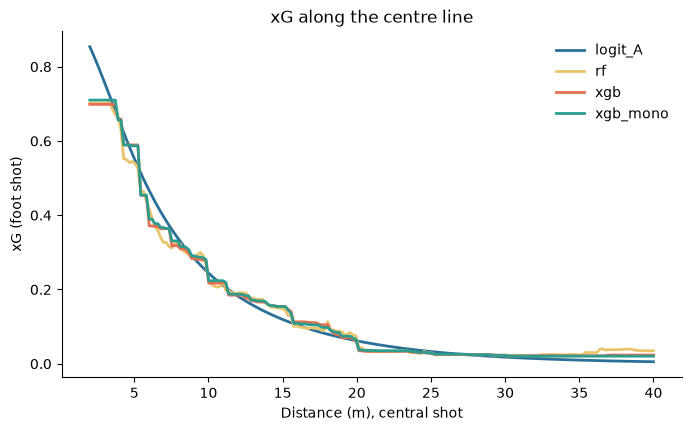

In [10]:
models = {
    "rf": make_random_forest(**RF_BEST),
    "xgb": make_xgboost(FEATURES_A, **XGB_BEST),
    "xgb_mono": make_xgboost(FEATURES_A, monotone=True, **XGB_MONO_BEST),
}
for est in models.values():
    est.fit(feature_matrix(train, FEATURES_A), train["is_goal"].astype(int))
logit_a = fit_logit(train, FEATURES_A)

dist = np.linspace(2, 40, 200)
line = pd.DataFrame({"distance": dist, "angle": shot_angle(105 - dist, 34), "header": 0.0, "counter_attack": 0.0})
curves = {"logit_A": predict_xg(logit_a, line, FEATURES_A)}
curves.update({name: est.predict_proba(line[FEATURES_A])[:, 1] for name, est in models.items()})

rises = {name: int((np.diff(c) > 1e-9).sum()) for name, c in curves.items()}
print("Number of places where xG goes UP as the shot moves away:", rises)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, c in curves.items():
    ax.plot(dist, c, label=name, color=COLORS[name], linewidth=2)
ax.set_xlabel("Distance (m), central shot")
ax.set_ylabel("xG (foot shot)")
ax.set_title("xG along the centre line")
ax.legend(frameon=False)
save(fig, "22_xg_vs_distance.png")

**Interpretation:**
- The logistic regression and the constrained XGBoost never go up. The **Random Forest** predicts in
  **steps** and goes up again in many places; the free XGBoost has a few small bumps. These bumps are noise
  from the training data, not football. A player whose shots get more xG for being further away would make
  the player analysis (Day 6) strange, so a monotone model is safer even if its log loss is the same.
- The two ends of the curve show where each model type is weak:
  - **Very close (under 4 m):** the trees stay flat at about 70%, the logistic regression climbs to about 85%.
    The real train goal rate there is about 68% (only 59 shots). The trees stay close to the data; the
    logistic regression extends its straight line into an area with very few shots.
  - **Far away (30 m+):** the trees stay around 2%, the logistic regression drops to about 1%. The real goal rate
    is flat at about 2% beyond 23 m, so here too the trees follow the data more closely. This matches the small
    under-prediction of long shots we saw on Day 4.
  - Both ends hold few shots, which is why the overall log loss barely changes.

## 7. Cross-validation comparison (train set, same folds for every model)
`GroupKFold` without shuffling gives the same 5 folds every time, so all models are scored on the
same matches and can be compared fold by fold.

In [11]:
cv_results = {"logit_A": cv_logit}
cv_results.update({name: cross_validate_estimator(est, train, FEATURES_A) for name, est in models.items()})

cv_summary = pd.DataFrame({
    name: {"log_loss": r["log_loss"].mean(), "log_loss_sd": r["log_loss"].std(),
           "brier": r["brier"].mean(), "roc_auc": r["roc_auc"].mean(),
           "folds_better_than_logit_A": int((r["log_loss"] < cv_logit["log_loss"]).sum())}
    for name, r in cv_results.items()
}).T
cv_summary.round(4)

,log_loss,log_loss_sd,brier,roc_auc,folds_better_than_logit_A
logit_A,0.2928,0.0081,0.0845,0.7782,0.0
rf,0.2934,0.0059,0.0852,0.7744,1.0
xgb,0.2929,0.0062,0.0848,0.7747,2.0
xgb_mono,0.2926,0.0062,0.0848,0.7759,3.0


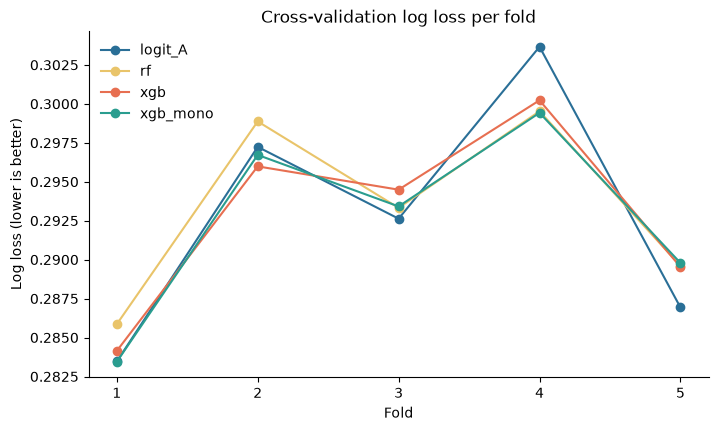

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, r in cv_results.items():
    ax.plot(r.index, r["log_loss"], marker="o", label=name, color=COLORS[name])
ax.set_xticks(range(1, 6))
ax.set_xlabel("Fold")
ax.set_ylabel("Log loss (lower is better)")
ax.set_title("Cross-validation log loss per fold")
ax.legend(frameon=False)
save(fig, "23_cv_comparison.png")

**Interpretation:** all four models are within about **0.001** log loss of each other, while one fold
differs from the next by about 0.02. The fold (which matches) matters ten times more than the model.
`xgb_mono` is the best on average by a hair, the Random Forest the worst; none of them wins every fold.

## 8. Final check on the test set (used once)

In [13]:
preds = all_test_predictions(train, test)
xg_cols = ["xg_logit_A", "xg_logit_B", "xg_rf", "xg_xgb", "xg_xgb_mono"]

test_results = compare_models({c[3:]: evaluate(preds["is_goal"], preds[c]) for c in ["xg_baseline"] + xg_cols})
test_results.round(4)

,shots,goals,xg,xg_per_goal,log_loss,brier,roc_auc
baseline,1696.0,176.0,185.2921,1.0528,0.3335,0.0930,0.5000
logit_A,1696.0,176.0,183.3446,1.0417,0.2753,0.0792,0.7982
logit_B,1696.0,176.0,182.0960,1.0346,0.2733,0.0788,0.8044
rf,1696.0,176.0,182.1889,1.0352,0.2765,0.0797,0.7946
xgb,1696.0,176.0,182.9005,1.0392,0.2762,0.0796,0.7943
xgb_mono,1696.0,176.0,182.5422,1.0372,0.2765,0.0797,0.7943


### 8.1 Is any difference real? Bootstrap by match
We resample the 76 test **matches** 2,000 times and recompute the log loss difference to `logit_A`
each time. Negative = better than `logit_A`. If the 95% interval contains 0, the test set cannot
tell the two models apart.

In [14]:
boot = pd.DataFrame({
    c[3:]: bootstrap_difference(preds["is_goal"], preds["xg_logit_A"], preds[c], preds["matchId"])
    for c in ["xg_logit_B", "xg_rf", "xg_xgb", "xg_xgb_mono"]
}).T
boot["clearly_different"] = (boot["ci_low"] > 0) | (boot["ci_high"] < 0)
boot.round(4)

,difference,ci_low,ci_high,clearly_different
logit_B,-0.0021,-0.0039,-0.0003,True
rf,0.0011,-0.0021,0.0042,False
xgb,0.0009,-0.0018,0.0035,False
xgb_mono,0.0011,-0.0017,0.0040,False


**Interpretation:**
- On the test set the tree models are slightly **worse** than `logit_A` (about +0.001 log loss),
  but all three intervals contain 0: **no real difference**.
- The only model that is clearly different is `logit_B` (with `score_diff`), which is slightly **better**.
  This matches Day 4: the score has a small real effect. Whether it belongs in xG is a separate
  question (see NOTES, Day 4).

### 8.2 Calibration

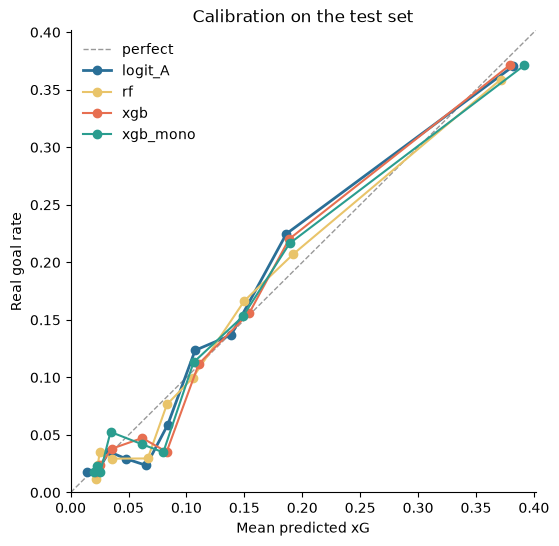

In [15]:
fig, ax = plt.subplots(figsize=(6, 6))
plot_calibration(ax, calibration_table(preds["is_goal"], preds["xg_logit_A"]), label="logit_A", color=COLORS["logit_A"])
for name in ["rf", "xgb", "xgb_mono"]:
    t = calibration_table(preds["is_goal"], preds[f"xg_{name}"])
    ax.plot(t["mean_xg"], t["goal_rate"], marker="o", linewidth=1.5, label=name, color=COLORS[name])
ax.legend(frameon=False)
ax.set_title("Calibration on the test set")
save(fig, "24_calibration_all.png")

**Interpretation:** all models follow the diagonal closely, and the total xG of every model is within
about 4% of the real goals. None of the tree models fixes the small over-prediction around 4-7% xG
that we saw on Day 4, so it is most likely noise in the 76 test matches rather than a model problem.

## 9. Which features matter? Permutation importance
For each feature we shuffle its values in the test set (breaking its link with the outcome) and measure
how much the log loss gets worse. Bigger increase = more important. We repeat the shuffle 10 times.
This works the same way for every model, so the models can be compared.

,logit_A,rf,xgb,xgb_mono
distance,0.0561,0.0249,0.0539,0.0392
angle,0.0181,0.0298,0.0166,0.0230
header,0.0115,0.0084,0.0106,0.0111
counter_attack,0.0043,0.0026,0.0040,0.0034


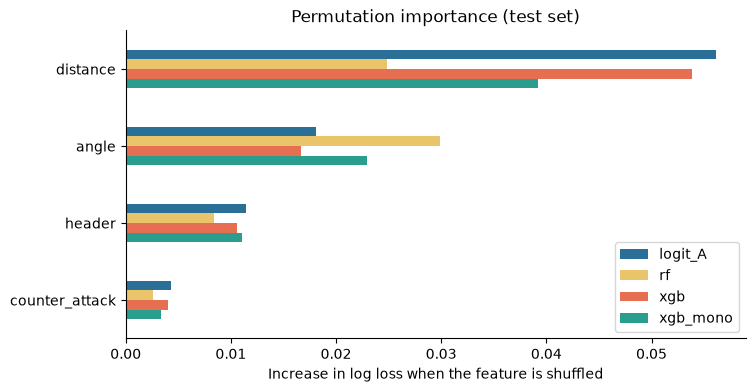

In [16]:
def permutation_importance_logloss(predict, df, features, n_repeats=10, seed=42):
    """Mean increase in log loss when each feature is shuffled."""
    rng = np.random.default_rng(seed)
    base = evaluate(df["is_goal"], predict(df))["log_loss"]
    out = {}
    for f in features:
        scores = []
        for _ in range(n_repeats):
            shuffled = df.copy()
            shuffled[f] = rng.permutation(shuffled[f].to_numpy())
            scores.append(evaluate(df["is_goal"], predict(shuffled))["log_loss"] - base)
        out[f] = np.mean(scores)
    return pd.Series(out)


predictors = {"logit_A": lambda d: predict_xg(logit_a, d, FEATURES_A)}
predictors.update({name: (lambda d, est=est: est.predict_proba(feature_matrix(d, FEATURES_A))[:, 1])
                   for name, est in models.items()})
importance = pd.DataFrame({name: permutation_importance_logloss(p, test, FEATURES_A) for name, p in predictors.items()})
display(importance.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
importance.plot.barh(ax=ax, color=[COLORS[c] for c in importance.columns])
ax.set_xlabel("Increase in log loss when the feature is shuffled")
ax.set_title("Permutation importance (test set)")
ax.invert_yaxis()
save(fig, "25_permutation_importance.png")

**Interpretation:**
- In the logistic regression and both XGBoost models, **distance** is clearly the most important
  feature, then angle, header and counter attack.
- The **Random Forest** puts angle slightly ahead of distance. Distance and angle are strongly related, and
  the forest spreads the same information over both: when one is shuffled, the other still carries much of it.
  So permutation importance of two correlated features must be read **together**: distance + angle dominate
  in every model.
- Header and counter attack have the same order and similar size in all models. The tree models use the
  same information as the logistic regression; they do not find anything new in these four features.

## 10. What the models see: xG maps
xG of a foot shot (no counter attack) over the attacking half, for three models.

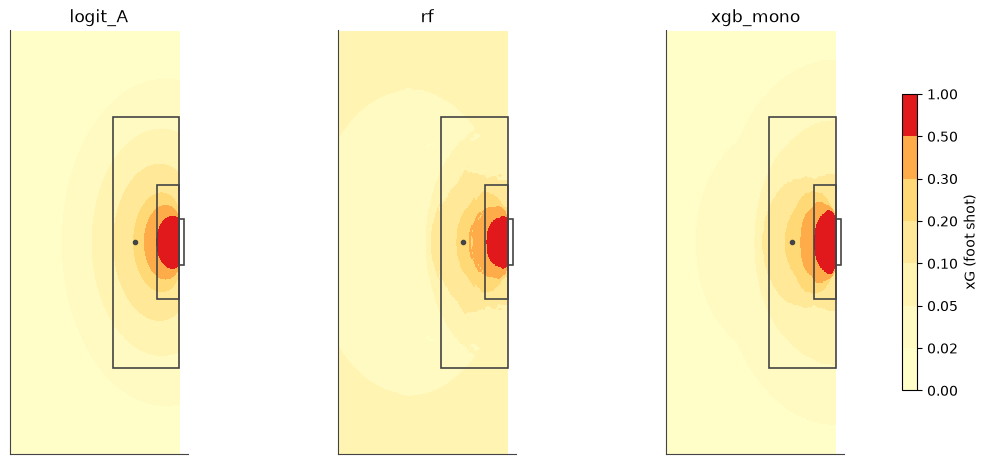

In [17]:
gx, gy = np.meshgrid(np.linspace(60, 100, 160), np.linspace(0, 100, 200))
gx_m, gy_m = to_meters(gx, gy)
grid = pd.DataFrame({"distance": distance_to_goal(gx_m, gy_m).ravel(), "angle": shot_angle(gx_m, gy_m).ravel(),
                     "header": 0.0, "counter_attack": 0.0})
maps = {"logit_A": predict_xg(logit_a, grid, FEATURES_A),
        "rf": models["rf"].predict_proba(grid[FEATURES_A])[:, 1],
        "xgb_mono": models["xgb_mono"].predict_proba(grid[FEATURES_A])[:, 1]}

levels = [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, (name, values) in zip(axes, maps.items()):
    cf = ax.contourf(gx, gy, values.reshape(gx.shape), levels=levels, cmap="YlOrRd", zorder=0)
    draw_half_pitch(ax)
    ax.set_xlim(60, 102)
    ax.set_title(name)
fig.colorbar(cf, ax=axes, label="xG (foot shot)", shrink=0.7)
save(fig, "26_xg_maps.png")

**Interpretation:** the logistic regression gives smooth, round zones. The Random Forest shows blocky,
uneven zones (it predicts in steps). The constrained XGBoost sits in between: flexible, but it still
follows the "closer and more central = better" rule.

## 11. Extra: does the score help the tree model?
Same check as Day 4 (`score_diff`), with the constrained XGBoost settings (cross-validation only).

In [18]:
cv_mono_b = cross_validate_estimator(make_xgboost(FEATURES_B, monotone=True, **XGB_MONO_BEST), train, FEATURES_B)
pd.DataFrame({
    "xgb_mono (A)": cv_results["xgb_mono"]["log_loss"],
    "xgb_mono (B)": cv_mono_b["log_loss"],
    "logit_A": cv_logit["log_loss"],
}).agg(["mean", "std"]).round(4)

,xgb_mono (A),xgb_mono (B),logit_A
mean,0.2926,0.2921,0.2928
std,0.0062,0.0064,0.0081


## 12. Save predictions for Hasan (Day 5 analysis)
`test_predictions.csv` now holds every model's xG for the same 1,696 test shots.
The same file is created by `python src/tree_models.py`.

In [19]:
preds.to_csv("../data/processed/test_predictions.csv", index=False)
print(list(preds.columns))

['id', 'matchId', 'teamId', 'playerId', 'is_goal', 'xg_baseline', 'xg_logit_A', 'xg_logit_B', 'xg_rf', 'xg_xgb', 'xg_xgb_mono']


## 13. Summary for the team
- **Tuned models (5-fold GroupKFold, log loss):** Random Forest depth 5 / 20+ shots per leaf;
  XGBoost depth 1 / 600 trees / learning rate 0.02; XGBoost with monotone constraints depth 2 / 600 trees / 0.01.
- **Nothing beats the logistic regression.** CV log loss: xgb_mono 0.2926, logit_A 0.2928, xgb 0.2929,
  rf 0.2934. On the test set the trees are about 0.001 worse, and the bootstrap intervals contain 0.
- **Why:** XGBoost of depth 1 (no interactions) is as good as depth 3, so the data has no useful
  interactions, and the relationships are smooth. That is the situation where logistic regression is enough.
- **Overfitting is real:** an unrestricted Random Forest scores 0.95 log loss (worse than guessing the average).
- **Football logic:** the Random Forest and free XGBoost sometimes give more xG further from goal;
  the constrained XGBoost and the logistic regression never do.
- **Recommendation:** keep **`logit_A`** as the main xG model (as good as the trees, smooth, monotone and
  easy to explain with odds ratios). `xgb_mono` is the best alternative if a tree model is wanted.
- **For Hasan (Day 5 analysis):** `data/processed/test_predictions.csv` has `xg_baseline`, `xg_logit_A`,
  `xg_logit_B`, `xg_rf`, `xg_xgb`, `xg_xgb_mono` for every test shot. Figures 22-26 are ready for the
  ROC-AUC / calibration comparison.